In [1]:
import pandas as pd
import numpy as np
from cyvcf2 import VCF
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt 
import matplotlib.cm as cm
import matplotlib.patches as mpatches
import statsmodels.stats.multitest as multi

# NOTE Important so when loading figures into illustrator the text is seen as text
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42 

In [2]:
%matplotlib inline

# Pval correct by bonferroni only on number of tests per gene and then take best pvalue and pass this set into FDR
def collect_per_gene_best_trs(assoc_df, output_prefix):
    # Grab total tests per gene and index of best pval per gene
    num_genes = assoc_df.groupby('gene').size()
    best_linear_pval_idx = assoc_df.groupby('gene')['p.linear'].idxmin()
    best_quad_pval_idx = assoc_df.groupby('gene')['p.quad'].idxmin()
    best_anova_pval_idx = assoc_df.groupby('gene')['p.anova'].idxmin()

    # Grab best pvals using index
    best_linear_pval = assoc_df.loc[best_linear_pval_idx]['p.linear']
    best_quad_pval = assoc_df.loc[best_quad_pval_idx]['p.quad']
    best_anova_pval = assoc_df.loc[best_anova_pval_idx]['p.anova']

    best_linear_pval.index = num_genes.index
    best_quad_pval.index = num_genes.index
    best_anova_pval.index = num_genes.index

    # Bonferroni Correction based on number of tests per gene
    bonf_linear_pval = best_linear_pval * num_genes
    bonf_quad_pval = best_quad_pval * num_genes
    bonf_anova_pval = best_anova_pval * num_genes
 
    # FDR test on best genes
    gene_corrected_linear_pval = multi.multipletests(bonf_linear_pval, method='fdr_bh')[1]
    gene_corrected_quad_pval = multi.multipletests(bonf_quad_pval, method='fdr_bh')[1]
    gene_corrected_anova_pval = multi.multipletests(bonf_anova_pval, method='fdr_bh')[1]

    # Create new dataframes for each pval type and output
    linear_df = assoc_df.loc[best_linear_pval_idx][['gene', 'chrom', 'str.start', 'beta', 'p.linear']]
    quad_df = assoc_df.loc[best_quad_pval_idx][['gene', 'chrom', 'str.start', 'b1', 'b2', 'p.quad']]
    anova_df = assoc_df.loc[best_anova_pval_idx][['gene','chrom','str.start','beta','p.linear','b1','b2','p.quad','p.anova']]

    linear_df['p.linear'] = gene_corrected_linear_pval
    quad_df['p.quad'] = gene_corrected_quad_pval
    anova_df['p.anova'] = gene_corrected_anova_pval

    sig_linear_df = set(linear_df[linear_df['p.linear'] <= 0.05]['gene'])
    sig_anova_df = set(anova_df[anova_df['p.anova'] <= 0.05]['gene'])
    linear_anova_overlap_df = sig_linear_df.intersection(sig_anova_df)

    # Output each dataframe
    linear_df.to_csv(output_prefix+"_linear_corrected_best_pvals.csv", index=False)
    quad_df.to_csv(output_prefix+"_quad_corrected_best_pvals.csv", index=False)
    anova_df.to_csv(output_prefix+"_anova_corrected_best_pvals.csv", index=False)

    # Output number of significant hits 
    print("Per Gene Significant hits")
    print(f"Linear significant hits: {linear_df[linear_df['p.linear'] <= 0.05].shape}")
    print(f"Quadratic significant hits: {quad_df[quad_df['p.quad'] <= 0.05].shape}")
    print(f"Anova significant hits: {anova_df[anova_df['p.anova'] <= 0.05].shape}")
    print(f"Linear Anova Overlap: {len(linear_anova_overlap_df)}")

    return num_genes


# None pvals in p.anova just means both the quadratic and linear had the same pval and learned same model
# Load Geuvadis Pvalues
geuv_assoc_file = "/storage/mlamkin/data/NonLinearSTRExpression/Geuvadis_nonlinear_associations/geuvadis_gene_expr_nonlinear_associations.tab"
geuv_assoc_df = pd.read_csv(geuv_assoc_file, delimiter='\t', usecols=['gene', 'chrom', 'str.start', 'beta', 'p.linear', 'b1', 'b2', 'p.quad', 'p.anova'])
geuv_assoc_df['gene'] = geuv_assoc_df['gene'].str.split('.').str[0]
geuv_assoc_df.fillna(1, inplace=True)
geuv_assoc_df['corrected_p.linear'] = multi.multipletests(geuv_assoc_df['p.linear'], method='fdr_bh')[1]
geuv_assoc_df['corrected_p.quad'] = multi.multipletests(geuv_assoc_df['p.quad'], method='fdr_bh')[1]
geuv_assoc_df['corrected_p.anova'] = multi.multipletests(geuv_assoc_df['p.anova'], method='fdr_bh')[1]
#geuv_assoc_df.to_csv("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_gene_expr_nonlinear_corrected_assocations.csv", index=False)

# How many sig hits in anova for overall correction
geuv_linear_sig = geuv_assoc_df[(geuv_assoc_df['corrected_p.linear'] <= 0.05)]
geuv_quad_sig = geuv_assoc_df[(geuv_assoc_df['corrected_p.quad'] <= 0.05)]
geuv_anova_sig = geuv_assoc_df[(geuv_assoc_df['corrected_p.anova'] <= 0.05)]

print("Geuvadis")
print(f"Total Geuvadis tests: {geuv_assoc_df.shape[0]}")
print(f"Total Geuvadis corrected linear sig tests: {geuv_linear_sig.shape[0]}")
print(f"Total Geuvadis corrected quad sig tests: {geuv_quad_sig.shape[0]}")
print(f"Total Geuvadis corrected anova sig tests: {geuv_anova_sig.shape[0]}")
geuv_per_gene_num_tests = collect_per_gene_best_trs(geuv_assoc_df, '/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_gene_expr')

# Load GTEx Pvalues
gtex_assoc_file = "/storage/mlamkin/data/NonLinearSTRExpression/GTEx_Analysis_v8/Association_Results/GTEx_v8_Cells_EBV-transformed_lymphocytes_associations.tab"
gtex_assoc_df = pd.read_csv(gtex_assoc_file, delimiter='\t', usecols=['gene', 'chrom', 'str.start', 'beta', 'p.linear', 'b1', 'b2', 'p.quad', 'p.anova'])
gtex_assoc_df['gene'] = gtex_assoc_df['gene'].str.split('.').str[0]
gtex_assoc_df.fillna(1, inplace=True)
#gtex_assoc_df.to_csv("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/GTEx_gene_expr_nonlinear_corrected_assocations.csv", index=False)

# How many sig hits in anova for overall correction
gtex_linear_sig = gtex_assoc_df[(gtex_assoc_df['p.linear'] <= 0.05)]
gtex_quad_sig = gtex_assoc_df[(gtex_assoc_df['p.quad'] <= 0.05)]
gtex_anova_sig = gtex_assoc_df[(gtex_assoc_df['p.anova'] <= 0.05)]

print("GTEx")
print(f"Total GTEx tests: {gtex_assoc_df.shape[0]}")
print(f"Total GTEx linear nominally sig tests: {gtex_linear_sig.shape[0]}")
print(f"Total GTEx quad nominally sig tests: {gtex_quad_sig.shape[0]}")
print(f"Total GTEx anova nominally sig tests: {gtex_anova_sig.shape[0]}")
gtex_per_gene_num_tests = collect_per_gene_best_trs(gtex_assoc_df, '/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/GTEx_gene_expr')

# NOTE GTEx has 22630 Genes and GTEx only has 12605 so we will have dropout of effects across sets
# Merge GTEx and Geuvadis to get overlap
gtex_sorted_df = gtex_assoc_df.sort_values(by='str.start')
geuv_sorted_df = geuv_assoc_df.sort_values(by='str.start')
shared_effects = pd.merge_asof(geuv_sorted_df, gtex_sorted_df, on='str.start', by=['gene', 'chrom'], suffixes=('_geuv', '_gtex'), direction='nearest', tolerance=5)
shared_effects = shared_effects[shared_effects['p.linear_gtex'].notna()] # Remove tests that has no Geuvadis values
shared_effects.drop_duplicates(inplace=True)
#shared_effects.to_csv("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/GTEx_Geuvadis_gene_expr_nonlinear_overlap_associations.csv", index=False)
linear_sig = shared_effects[(shared_effects['corrected_p.linear'] <= 0.05) & (shared_effects['p.linear_gtex'] <= 0.05)]
quad_sig = shared_effects[(shared_effects['corrected_p.quad'] <= 0.05) & (shared_effects['p.quad_gtex'] <= 0.05)]
anova_sig = shared_effects[(shared_effects['corrected_p.anova'] <= 0.05) & (shared_effects['p.anova_gtex'] <= 0.05)]

print("Shared Variants")
print(f"Total shared tests: {shared_effects.shape[0]}")
print(f"Total shared linear sig tests (Both GTEx and Geuv): {linear_sig.shape[0]}")
print(f"Total shared quad sig tests (Both GTEx and Geuv): {quad_sig.shape[0]}")
print(f"Total shared anova sig tests (Both GTEx and Geuv): {anova_sig.shape[0]}")
print(shared_effects[(shared_effects['gene'] == 'ENSG00000107719') & (shared_effects['str.start'] == 70473892)].to_string())
print(shared_effects[(shared_effects['gene'] == 'ENSG00000163576') & (shared_effects['str.start'] == 19947266)].to_string())

# Limit to effects where geuvadis corrected was significant
shared_linear_sig = shared_effects[shared_effects['corrected_p.linear'] <= 0.05]
shared_quad_sig = shared_effects[shared_effects['corrected_p.quad'] <= 0.05]
shared_anova_sig = shared_effects[shared_effects['corrected_p.anova'] <= 0.05]

Geuvadis
Total Geuvadis tests: 3427940
Total Geuvadis corrected linear sig tests: 88809
Total Geuvadis corrected quad sig tests: 100674
Total Geuvadis corrected anova sig tests: 15040
Per Gene Significant hits
Linear significant hits: (3266, 5)
Quadratic significant hits: (3339, 6)
Anova significant hits: (2255, 9)
Linear Anova Overlap: 2003
GTEx
Total GTEx tests: 1507074
Total GTEx linear nominally sig tests: 108474
Total GTEx quad nominally sig tests: 109487
Total GTEx anova nominally sig tests: 38442
Per Gene Significant hits
Linear significant hits: (1952, 5)
Quadratic significant hits: (2029, 6)
Anova significant hits: (364, 9)
Linear Anova Overlap: 307
Shared Variants
Total shared tests: 564625
Total shared linear sig tests (Both GTEx and Geuv): 8031
Total shared quad sig tests (Both GTEx and Geuv): 8574
Total shared anova sig tests (Both GTEx and Geuv): 816
                    gene  chrom  str.start  beta_geuv  p.linear_geuv   b1_geuv   b2_geuv   p.quad_geuv  p.anova_geuv  corre

Nu unique genes: (3837,)
Num Sig Effects: 16961 Correlation Coeff: 0.7513046611376147 P-value: 0.0
15131


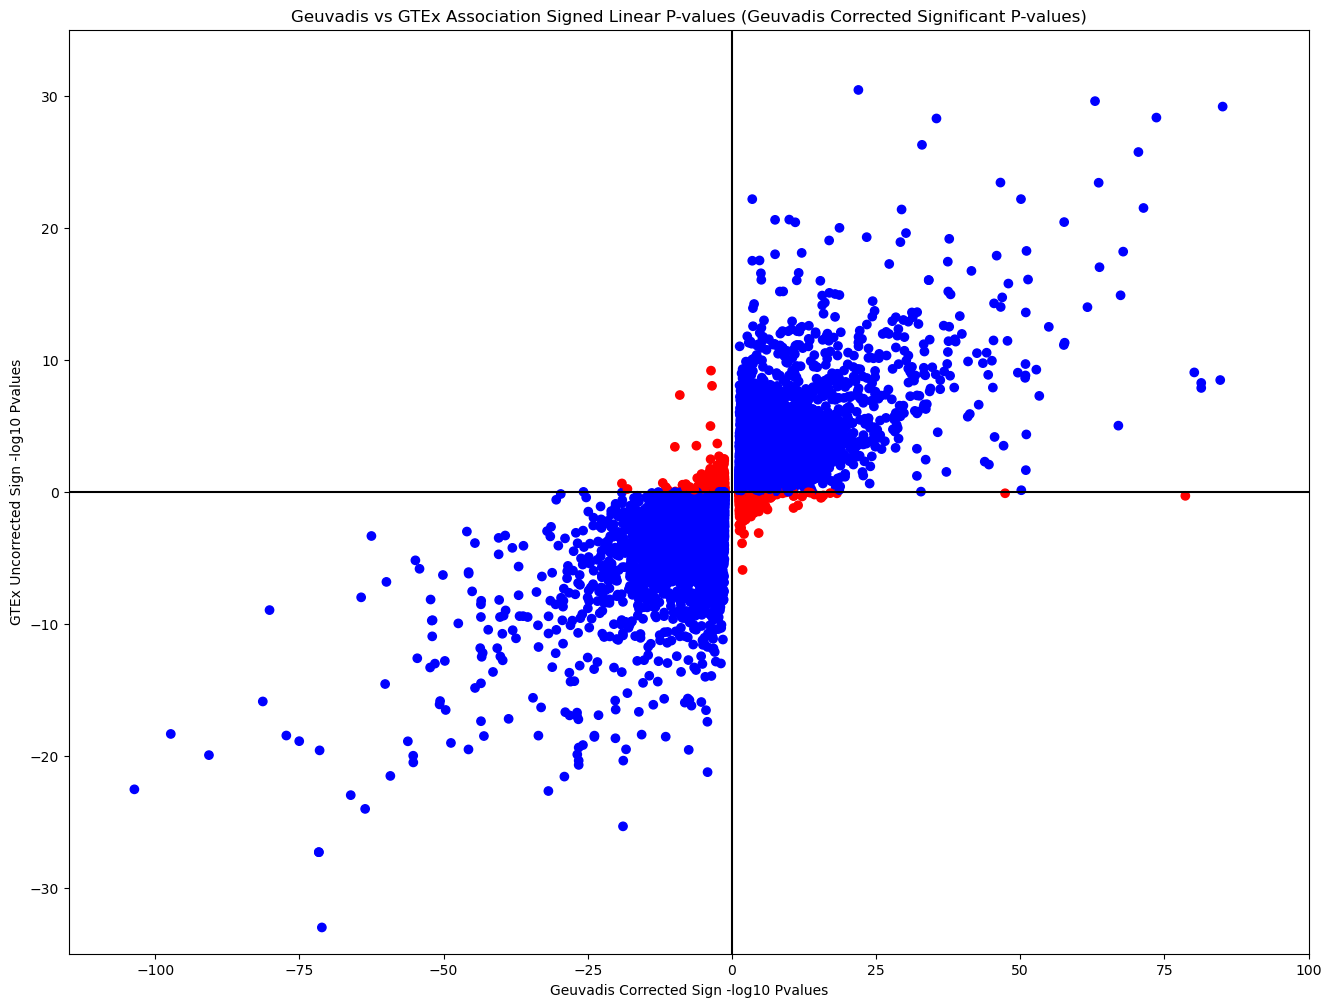

In [4]:
# Plot geuvadis signficiant effects against gtex effects (IE only use the set of variants where they were significant in corrected Geuvadis data)
# Geuvadis info
geuv_lin_sign = np.sign(shared_linear_sig['beta_geuv'])
geuv_lin_pvals = -1*np.log10(shared_linear_sig['corrected_p.linear'])

# GTEx info
gtex_lin_sign = np.sign(shared_linear_sig['beta_gtex'])
gtex_lin_pvals = -1*np.log10(shared_linear_sig['p.linear_gtex'])

# Calculate Correlation
corr_coeff, pval = stats.pearsonr(geuv_lin_sign*geuv_lin_pvals, gtex_lin_sign*gtex_lin_pvals)
print(f"Num unique genes: {shared_linear_sig['gene'].unique().shape}")
print(f"Num Sig Effects: {shared_linear_sig.shape[0]} Correlation Coeff: {corr_coeff} P-value: {pval}")

# Plot linear pvals
fig = plt.figure(figsize=(16,12))
ax = fig.add_subplot(1,1,1)
ax.set_title("Geuvadis vs GTEx Association Signed Linear P-values (Geuvadis Corrected Significant P-values)")
ax.set_xlabel('Geuvadis Corrected Sign -log10 Pvalues')
ax.set_ylabel("GTEx Uncorrected Sign -log10 Pvalues")
ax.set_ylim(-35,35)
ax.set_xlim(-115, 100)
ax.vlines(0, -35, 35, color='black')
ax.hlines(0, -115, 100, color='black')
pval_colors = np.where(geuv_lin_sign*gtex_lin_sign > 0, 'blue', 'red')
print(np.sum(pval_colors=='blue'))
ax.scatter(geuv_lin_sign*geuv_lin_pvals, gtex_lin_sign*gtex_lin_pvals, color=pval_colors)
plt.show()

fig.savefig("/storage/mlamkin/data/GeneExprPredictor/paper_figures/Geuvaidis_GTEx_linear_pvals.pdf")


                    gene  chrom  str.start    b1_geuv   b2_geuv    b1_gtex   b2_gtex  corrected_p.quad   p.quad_gtex
247402   ENSG00000181240  chr19    6439385  -1.146200  0.052671  -0.129239 -0.003108      4.135741e-54  1.854583e-08
594092   ENSG00000166796  chr11   18409902  -0.011197  0.007287   1.182338 -0.082219      2.059176e-55  2.418522e-13
861696   ENSG00000204644   chr6   29676099   0.135759  0.003604   0.107914 -0.002006      1.219910e-52  2.660877e-14
1286368  ENSG00000137806  chr15   41443603  -1.129757  0.106281  15.875856 -0.708197      8.372741e-52  4.120889e-15
1299643  ENSG00000141698  chr17   41826211  -0.509028  0.090319   9.863518 -0.776045      1.476765e-58  1.075745e-17
1300112  ENSG00000141698  chr17   41839880   0.116621 -0.035529  -5.748239  0.134677      3.467850e-53  4.606700e-13
1347122  ENSG00000124587   chr6   42956958   1.225529 -0.116599 -16.058271  0.708623      1.355266e-91  5.113130e-24
1955642  ENSG00000242550  chr18   63878372   0.720497 -0.095266 

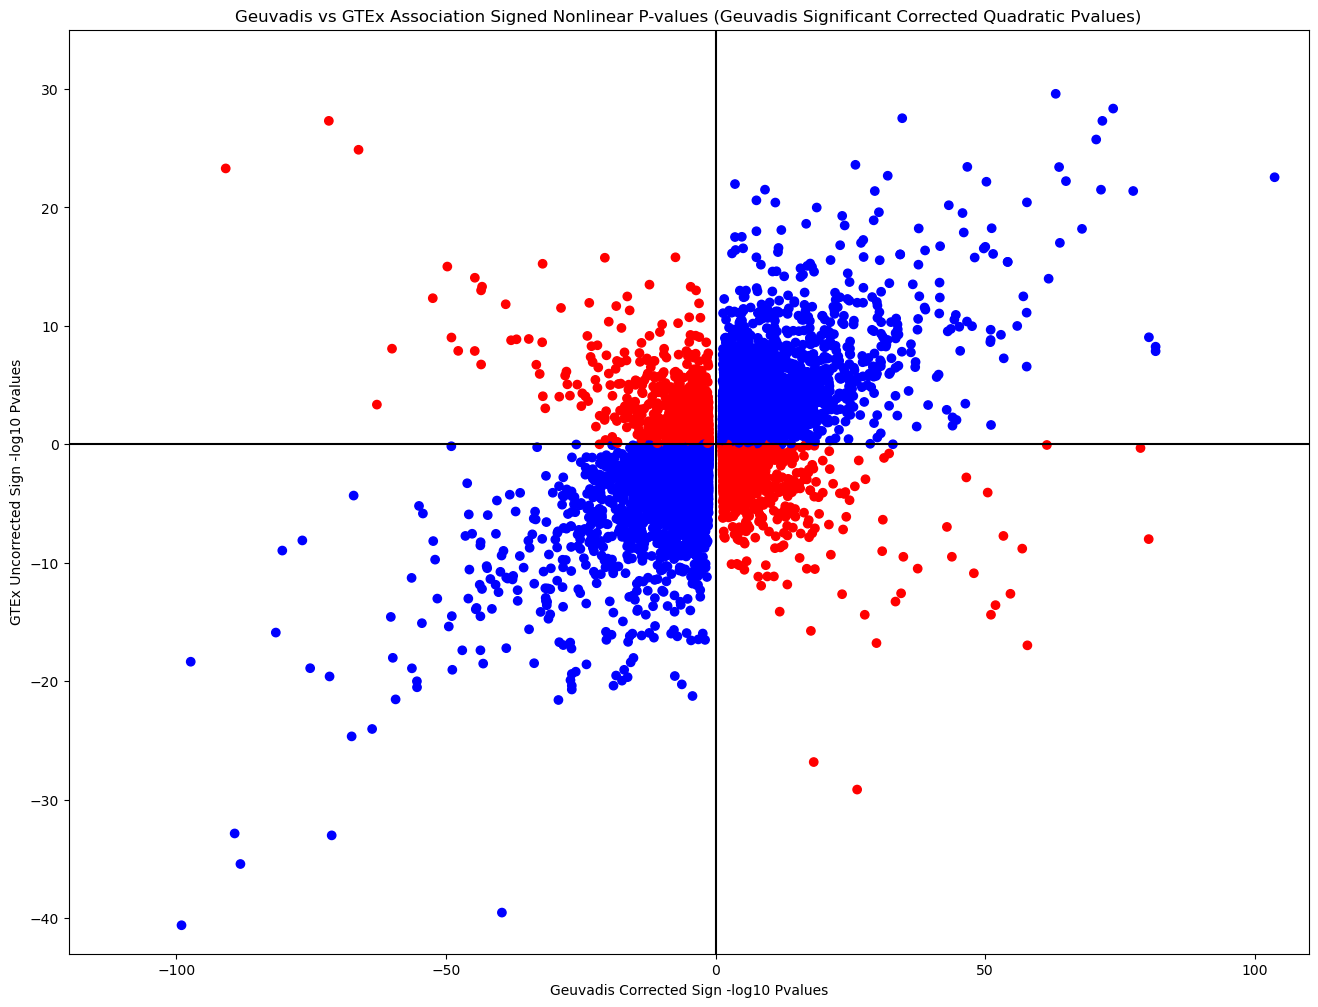

14013
Nu unique genes: (3997,)
Num Sig Effects: 18545 Correlation Coeff: 0.5301663924501914 P-value: 0.0


In [5]:
# Plot geuvadis signficiant effects against gtex effects (IE only use the set of variants where they were significant in corrected Geuvadis quad pval data)
geuv_nonlin_sign = np.sign(shared_quad_sig['b2_geuv'])
geuv_nonlin_pvals = -1*np.log10(shared_quad_sig['corrected_p.quad'])
gtex_nonlin_sign = np.sign(shared_quad_sig['b2_gtex'])
gtex_nonlin_pvals = -1*np.log10(shared_quad_sig['p.quad_gtex'])

strong_pval_df = shared_quad_sig[(np.sign(shared_quad_sig['b2_geuv']) != np.sign(shared_quad_sig['b2_gtex'])) & (-1*np.log10(shared_quad_sig['corrected_p.quad']) > 50)]
print(strong_pval_df[['gene', 'chrom', 'str.start', 'b1_geuv', 'b2_geuv', 'b1_gtex', 'b2_gtex', 'corrected_p.quad', 'p.quad_gtex']].to_string())

# Plot nonlinear pvals
fig = plt.figure(figsize=(16,12))
ax = fig.add_subplot(1,1,1)
ax.set_title("Geuvadis vs GTEx Association Signed Nonlinear P-values (Geuvadis Significant Corrected Quadratic Pvalues)")
ax.set_xlabel('Geuvadis Corrected Sign -log10 Pvalues')
ax.set_ylabel("GTEx Uncorrected Sign -log10 Pvalues")
ax.set_ylim(-43,35)
ax.set_xlim(-120, 110)
ax.vlines(0, -43, 35, color='black')
ax.hlines(0, -120, 110, color='black')
nonlin_pval_colors = np.where(geuv_nonlin_sign*gtex_nonlin_sign > 0, 'blue', 'red')
ax.scatter(geuv_nonlin_sign*geuv_nonlin_pvals, gtex_nonlin_sign*gtex_nonlin_pvals, color=nonlin_pval_colors)
plt.show()

fig.savefig("/storage/mlamkin/data/GeneExprPredictor/paper_figures/Geuvaidis_GTEx_nonlinear_pvals.pdf")

# Calculate Correlation
print(np.sum(nonlin_pval_colors=='blue'))
corr_coeff, pval = stats.pearsonr(geuv_nonlin_sign*geuv_nonlin_pvals, gtex_nonlin_sign*gtex_nonlin_pvals)
print(f"Nu unique genes: {shared_quad_sig['gene'].unique().shape}")
print(f"Num Sig Effects: {shared_quad_sig.shape[0]} Correlation Coeff: {corr_coeff} P-value: {pval}")

Nu unique genes: (1145,)
Num Sig Effects: 1943 Correlation Coeff: 0.49607630036817596 P-value: 3.1569761089940203e-121


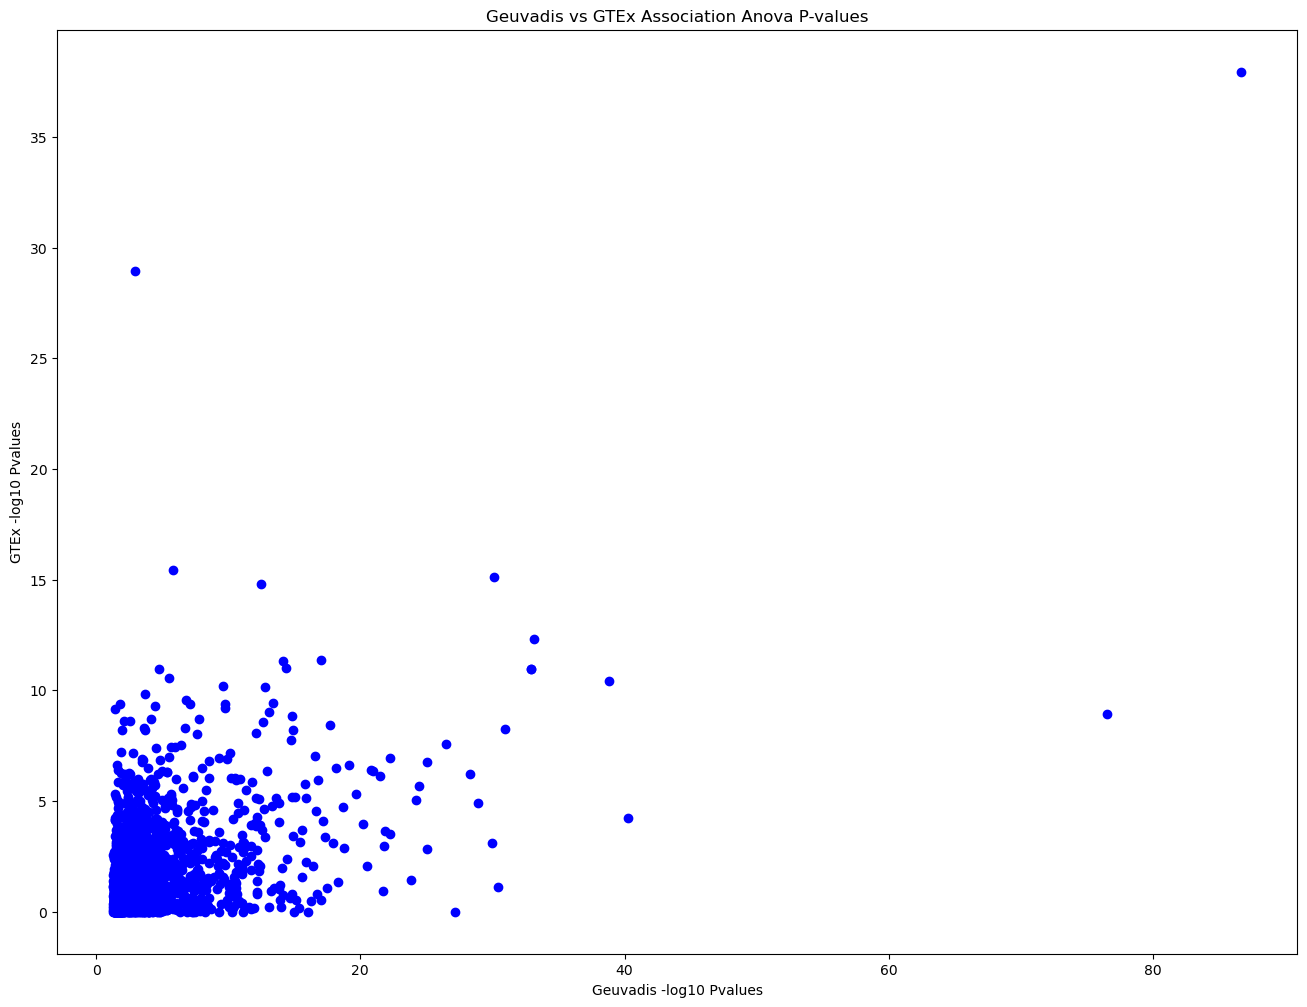

In [6]:
# Limit to only geuvadis significant effects (IE corrected anova pvalues were signficant in Geuvadis)
geuv_anova_pvals = -1*np.log10(shared_anova_sig['corrected_p.anova'])
gtex_anova_pvals = -1*np.log10(shared_anova_sig['p.anova_gtex'])

# Calculate Correlation
corr_coeff, pval = stats.pearsonr(geuv_anova_pvals, gtex_anova_pvals)
print(f"Nu unique genes: {shared_anova_sig['gene'].unique().shape}")
print(f"Num Sig Effects: {shared_anova_sig.shape[0]} Correlation Coeff: {corr_coeff} P-value: {pval}")

# Plot anova unsigned pvals
fig = plt.figure(figsize=(16,12))
ax = fig.add_subplot(1,1,1)
ax.set_title("Geuvadis vs GTEx Association Anova P-values")
ax.set_xlabel('Geuvadis -log10 Pvalues')
ax.set_ylabel("GTEx -log10 Pvalues")
ax.scatter(geuv_anova_pvals, gtex_anova_pvals, color='b')
plt.show()

In [3]:
# NOTE only run this to remake the overlapping effects file with repeat units

# Load Master Table to grab metadata
# rsq_df = pd.read_csv(
#     "/storage/mlamkin/data/GeneExprPredictor/Geuvadis_master_table.txt", 
#     delimiter='\t', 
#     usecols=[
#         'gene_name',
#         'gene',
#         'str.start',
#         'afreq_EUR', 
#         'het_EUR',
#     ]
# )

# metadata_df = geuv_assoc_df.merge(rsq_df, left_on=['gene', 'str.start'], right_on=['gene', 'str.start'])
# metadata_df.drop_duplicates(inplace=True)

# #Collect repeat unit for each variant
# for chrom in range(1,23):
#     print(chrom)
#     repeat_units = []
#     vcf_file = f"/gymreklab-tscc/mlamkin/GeneExprPredictor_data/STR_vcfs/ensemble_chr{chrom}_filtered.vcf.gz"
#     vcf = VCF(vcf_file)
#     per_chrom_df = metadata_df[metadata_df['chrom'] == f"chr{chrom}"]
#     for ind, var_info in per_chrom_df.iterrows():
#         region = f"{var_info['chrom']}:{var_info['str.start']}-{var_info['str.start']+1}"
#         for variant in vcf(region):
#             repeat_units.append(variant.INFO['RU'])
#             break
#     per_chrom_df['repeat_unit'] = repeat_units
#     per_chrom_df.to_csv(f"/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_chr{chrom}_associations_with_metadata.csv", index=False)

# #Combine the chrom dataframes into a single one and output
# repeat_unit_df = pd.DataFrame()
# for chrom in range(1,23):
#     df = pd.read_csv(f"/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_chr{chrom}_associations_with_metadata.csv")
#     repeat_unit_df = pd.concat([repeat_unit_df, df])

# repeat_unit_df.to_csv(f"/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_associations_with_metadata.csv", index=False)

1


/storage/mlamkin/tmp/ipykernel_5948/1646543002.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  per_chrom_df['repeat_unit'] = repeat_units


2


/storage/mlamkin/tmp/ipykernel_5948/1646543002.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  per_chrom_df['repeat_unit'] = repeat_units


3


...

/storage/mlamkin/tmp/ipykernel_5948/1646543002.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  per_chrom_df['repeat_unit'] = repeat_units


21


/storage/mlamkin/tmp/ipykernel_5948/1646543002.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  per_chrom_df['repeat_unit'] = repeat_units


22


/storage/mlamkin/tmp/ipykernel_5948/1646543002.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  per_chrom_df['repeat_unit'] = repeat_units


In [4]:
# Grab Metadata about the significant shared nonlinear TRs (p.anova sig)
metadata_df = pd.read_csv("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_associations_with_metadata.csv")
repeat_units = metadata_df['repeat_unit'].drop_duplicates()

# Overall table setup (Run for all TRs tested that were shared, signficiant (linear or quad))
#    Rows: Anova significant in both (No, Yes)
#    Cols: Heterozygosity (H = 1 - sum_i p_i^2) > 0.10 (No, Yes), Repeat Unit, Homopolymer
def setup_fisher_table(data_df, col_name, col_thresh=None, col_equal=None, col_ru=None):
    anova_sig = data_df[(data_df['corrected_p.anova'] <= 0.05)] #& (data_df['p.anova_gtex'] <= 0.05)]
    anova_not_sig = data_df[(data_df['corrected_p.anova'] > 0.05)] #| (data_df['p.anova_gtex'] > 0.05)]

    # Filter on col criterion since rows will always be the same for the table
    if col_thresh is not None:
        anova_sig_col_thresh = anova_sig[anova_sig[col_name] > col_thresh].shape[0]
        anova_not_sig_col_thresh = anova_not_sig[anova_not_sig[col_name] > col_thresh].shape[0]
    elif col_equal is not None:
        anova_sig_col_thresh = anova_sig[anova_sig[col_name] == col_equal].shape[0]
        anova_not_sig_col_thresh = anova_not_sig[anova_not_sig[col_name] == col_equal].shape[0]
    elif col_ru is not None:
        anova_sig_col_thresh = anova_sig[anova_sig[col_name].str.len() == col_ru].shape[0]
        anova_not_sig_col_thresh = anova_not_sig[anova_not_sig[col_name].str.len() == col_ru].shape[0]

    table = np.array([
        [anova_not_sig.shape[0] - anova_not_sig_col_thresh, anova_not_sig_col_thresh],
        [anova_sig.shape[0] - anova_sig_col_thresh, anova_sig_col_thresh]
    ])

    return table

def pretty_print_table(table):
    print("              | Col not true | Col true")
    print(f"Anova Not Sig | {table[0,0]} | {table[0,1]}")
    print(f"Anova Sig     | {table[1,0]} | {table[1,1]}")
    return

def het_comparison(metadata_df):
    print("Heterozygosity Mann Whitney Test (Anova Significant Greater)")
    # Heterozygosity Mann Whitney Test 
    #    Compare the heterozygosity values between the  set of variants that are anova p value corrected significant and not 
    het_anova_sig = metadata_df[metadata_df['corrected_p.anova'] <= 0.05 ]['het_EUR'].dropna()
    het_anova_not_sig = metadata_df[metadata_df['corrected_p.anova'] > 0.05]['het_EUR'].dropna()
    all_data_het = stats.mannwhitneyu(het_anova_sig, het_anova_not_sig, alternative='greater')
    print(f"Num Anova Sig: {het_anova_sig.shape} Num not Anova sig: {het_anova_not_sig.shape} P-value: {all_data_het.pvalue}")
    return

def repeat_fisher_exact(metadata_df, col, col_criterion, col_type=None):
    if col_type == 'equal':
        repeat_unit_table = setup_fisher_table(metadata_df, col, col_equal=col_criterion)
    elif col_type == 'ru':
        repeat_unit_table = setup_fisher_table(metadata_df, col, col_ru=col_criterion)
    else:
        raise Exception
    all_data_repeat_unit = stats.fisher_exact(repeat_unit_table)
    if all_data_repeat_unit.pvalue <= 0.05:
        pretty_print_table(repeat_unit_table)
    print(f"Stat: {all_data_repeat_unit.statistic} P-value: {all_data_repeat_unit.pvalue}")
    return np.array([(f'RU_{col_criterion}', all_data_repeat_unit.statistic, all_data_repeat_unit.pvalue, repeat_unit_table[1,1])], dtype=dtype)

# Build tables on two different sets.
#      1. All shared variants tested
#      2. Only significant variants (Linear or Quad significant)

# Set 1. All shared variants
dtype = np.dtype([('table_type', 'U20'), ('odds_ratio', 'f8'), ('pval', 'f8'), ('num_pass_both', 'i4')])

all_shared_summary = np.empty(0, dtype=dtype)

# Heterozygosity value
print(f"Dataset All Geuvadis Variants {metadata_df.shape}")
het_comparison(metadata_df)

"""
# Repeat Unit tests
print("Repeat Unit Tables")
print(repeat_units.shape)
for repeat_unit in repeat_units:
    print(f"Repeat Unit: {repeat_unit}")
    ru_fisher_exact_data = repeat_fisher_exact(metadata_df, 'repeat_unit', repeat_unit, col_type='equal')
    all_shared_summary = np.append(all_shared_summary, ru_fisher_exact_data)

print("Repeat Unit Length (1-6)")
for i in range(6):
    print(f"Repeat Unit Length: {i+1}")
    ru_len_fisher_exact_data = repeat_fisher_exact(metadata_df, 'repeat_unit', i+1, col_type='ru')
    all_shared_summary = np.append(all_shared_summary, ru_len_fisher_exact_data)

#np.savetxt("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_metadata_enrichment.csv", all_shared_summary, fmt='%s,%s,%s,%d', header='table_type,odds_ratio,pvalue,num_pass_both', comments='')

"""

# Set 2. Significant Variants
sig_var_df = metadata_df[(metadata_df['corrected_p.linear'] <= 0.05) | (metadata_df['corrected_p.quad'] <= 0.05)]
sig_var_summary = np.empty(0, dtype=dtype)

print(f"Dataset Significant Geuvadis Variants (Corrected Geuvadis Linear/Quad) {sig_var_df.shape}")
het_comparison(sig_var_df)

"""

print("Repeat Unit Tables")
for repeat_unit in repeat_units:
    print(f"Repeat Unit: {repeat_unit}")
    ru_fisher_exact_data = repeat_fisher_exact(sig_var_df, 'repeat_unit', repeat_unit, col_type='equal')
    sig_var_summary = np.append(sig_var_summary, ru_fisher_exact_data)

print("Repeat Unit Length (1-6)")
for i in range(6):
    print(f"Repeat Unit Length: {i+1}")
    ru_len_fisher_exact_data = repeat_fisher_exact(sig_var_df, 'repeat_unit', i+1, col_type='ru')
    sig_var_summary = np.append(sig_var_summary, ru_len_fisher_exact_data)

# Filter out NA variants
sig_var_summary = sig_var_summary[~np.isnan(sig_var_summary['odds_ratio'])]

#np.savetxt("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_sig_vars_metadata_enrichment.csv", sig_var_summary, fmt='%s,%s,%s,%d', header='table_type,odds_ratio,pvalue,num_pass_both', comments='')
"""

# Set 3. Unique TRs all

# Grab TR with lowest pvalue for corrected_p.anova
sorted_metadata_df = metadata_df.sort_values('corrected_p.anova', ascending=True)
unique_trs_df = sorted_metadata_df.drop_duplicates(subset=['chrom', 'str.start'], keep='first')
print(f"Set of Unique TRs in Geuvadis: {unique_trs_df.shape}")
unique_trs_shared_summary = np.empty(0, dtype=dtype)

# Heterozygosity value
print("Dataset All Unique TRs")
het_comparison(unique_trs_df)
"""
# Repeat Unit tests
print("Repeat Unit Tables")
print(repeat_units.shape)
for repeat_unit in repeat_units:
    print(f"Repeat Unit: {repeat_unit}")
    ru_fisher_exact_data = repeat_fisher_exact(unique_trs_df, 'repeat_unit', repeat_unit, col_type='equal')
    unique_trs_shared_summary = np.append(unique_trs_shared_summary, ru_fisher_exact_data)

print("Repeat Unit Length (1-6)")
for i in range(6):
    print(f"Repeat Unit Length: {i+1}")
    ru_len_fisher_exact_data = repeat_fisher_exact(unique_trs_df, 'repeat_unit', i+1, col_type='ru')
    unique_trs_shared_summary = np.append(unique_trs_shared_summary, ru_len_fisher_exact_data)

np.savetxt("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_unique_trs_metadata_enrichment.csv", unique_trs_shared_summary, fmt='%s,%s,%s,%d', header='table_type,odds_ratio,pvalue,num_pass_both', comments='')

"""

# Set 4. Unique TRs significant linear or quad
sig_trs_df = unique_trs_df[(unique_trs_df['corrected_p.linear'] <= 0.05) | (unique_trs_df['corrected_p.quad'] <= 0.05)]
sig_trs_shared_summary = np.empty(0, dtype=dtype)

# Heterozygosity value
print(f"Dataset Significant Unique TRs: {sig_trs_df.shape}")
het_comparison(sig_trs_df)

"""

# Repeat Unit tests
print("Repeat Unit Tables")
print(repeat_units.shape)
for repeat_unit in repeat_units:
    print(f"Repeat Unit: {repeat_unit}")
    ru_fisher_exact_data = repeat_fisher_exact(sig_trs_df, 'repeat_unit', repeat_unit, col_type='equal')
    sig_trs_shared_summary = np.append(sig_trs_shared_summary, ru_fisher_exact_data)

print("Repeat Unit Length (1-6)")
for i in range(6):
    print(f"Repeat Unit Length: {i+1}")
    ru_len_fisher_exact_data = repeat_fisher_exact(sig_trs_df, 'repeat_unit', i+1, col_type='ru')
    sig_trs_shared_summary = np.append(sig_trs_shared_summary, ru_len_fisher_exact_data)

np.savetxt("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_unique_sig_trs_metadata_enrichment.csv", sig_trs_shared_summary, fmt='%s,%s,%s,%d', header='table_type,odds_ratio,pvalue,num_pass_both', comments='')
"""

Dataset All Geuvadis Variants (3101278, 16)
Heterozygosity Mann Whitney Test (Anova Significant Greater)
Num Anova Sig: (14812,) Num not Anova sig: (3085436,) P-value: 0.0
Dataset Significant Geuvadis Variants (Corrected Geuvadis Linear/Quad or GTEx Linear Quad) (107174, 16)
Heterozygosity Mann Whitney Test (Anova Significant Greater)
Num Anova Sig: (14812,) Num not Anova sig: (92349,) P-value: 0.0
Set of Unique TRs in Geuvadis: (477018, 16)
Dataset All Unique TRs
Heterozygosity Mann Whitney Test (Anova Significant Greater)
Num Anova Sig: (12707,) Num not Anova sig: (464220,) P-value: 0.0
Dataset Significant Unique TRs: (32982, 16)
Heterozygosity Mann Whitney Test (Anova Significant Greater)
Num Anova Sig: (12707,) Num not Anova sig: (20264,) P-value: 9.46614883235251e-186


'\n\n# Repeat Unit tests\nprint("Repeat Unit Tables")\nprint(repeat_units.shape)\nfor repeat_unit in repeat_units:\n    print(f"Repeat Unit: {repeat_unit}")\n    ru_fisher_exact_data = repeat_fisher_exact(sig_trs_df, \'repeat_unit\', repeat_unit, col_type=\'equal\')\n    sig_trs_shared_summary = np.append(sig_trs_shared_summary, ru_fisher_exact_data)\n\nprint("Repeat Unit Length (1-6)")\nfor i in range(6):\n    print(f"Repeat Unit Length: {i+1}")\n    ru_len_fisher_exact_data = repeat_fisher_exact(sig_trs_df, \'repeat_unit\', i+1, col_type=\'ru\')\n    sig_trs_shared_summary = np.append(sig_trs_shared_summary, ru_len_fisher_exact_data)\n\nnp.savetxt("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_unique_sig_trs_metadata_enrichment.csv", sig_trs_shared_summary, fmt=\'%s,%s,%s,%d\', header=\'table_type,odds_ratio,pvalue,num_pass_both\', comments=\'\')\n'

In [ ]:
_shared_summary = np.append(unique_trs_shared_summary, ru_fisher_exact_data)

print("Repeat Unit Length (1-6)")
for i in range(6):
    print(f"Repeat Unit Length: {i+1}")
    ru_len_fisher_exact_data = repeat_fisher_exact(metadata_df, 'repeat_unit', i+1, col_type='ru')
    unique_trs_shared_summary = np.append(unique_trs_shared_summary, ru_len_fisher_exact_data)



In [4]:
dtype = np.dtype([('table_type', 'U20'), ('odds_ratio', 'f8'), ('pval', 'f8'), ('num_pass_both', 'i4')])
all_shared_summary = np.loadtxt("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_unique_trs_metadata_enrichment.csv", dtype=dtype, delimiter=',', skiprows=1)
sig_var_summary = np.loadtxt("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_unique_sig_trs_metadata_enrichment.csv", dtype=dtype, delimiter=',', skiprows=1)

##### Analysis of Enrichment tables which have best odds ratio etc #####
minimum_sig_hit_threshold = 10

# Filter out the tables that had less than the minimum hit threshold
filtered_all_shared_summary = all_shared_summary[all_shared_summary['num_pass_both'] >= minimum_sig_hit_threshold]
filtered_sig_var_summary = sig_var_summary[sig_var_summary['num_pass_both'] >= minimum_sig_hit_threshold]

# Reverse sort so largest odds ratio is first
sorted_all_shared_summary = np.sort(filtered_all_shared_summary, order='odds_ratio')[::-1]
sorted_sig_var_summary = np.sort(filtered_sig_var_summary, order='odds_ratio')[::-1]

print("All Association Tests in Geuvadis")
print(sorted_all_shared_summary[sorted_all_shared_summary['pval'] <= 0.05])

print("Significant Associations in Geuvadis")
print(sorted_sig_var_summary[sorted_sig_var_summary['pval'] <= 0.05])


All Association Tests in Geuvadis
[('RU_1', 1.72647059, 1.10385880e-140, 10269)
 ('RU_A', 1.70846098, 2.46548931e-137, 10209)
 ('RU_AAAT', 0.84494352, 6.99783913e-003,   261)
 ('RU_AAAAT', 0.72992245, 1.85337076e-002,    55)
 ('RU_AC', 0.72609279, 2.08927471e-023,   988)
 ('RU_AAC', 0.68579694, 2.30452319e-003,    63)
 ('RU_AAT', 0.66608993, 1.56245646e-005,   104)
 ('RU_2', 0.66261809, 1.12083996e-051,  1402)
 ('RU_AAAAG', 0.65356026, 4.47332187e-003,    43)
 ('RU_AT', 0.64260892, 2.46540298e-014,   271)
 ('RU_5', 0.64016508, 3.92214904e-011,   200)
 ('RU_AAAAC', 0.62501751, 1.00936713e-004,    63)
 ('RU_3', 0.6229998 , 1.54620875e-013,   219)
 ('RU_AAAC', 0.60175455, 4.27297697e-008,   103)
 ('RU_4', 0.59459321, 2.78909899e-036,   534)
 ('RU_AG', 0.53471651, 7.52206209e-016,   140)
 ('RU_ATCC', 0.46684013, 3.42385383e-003,    13)
 ('RU_AAGG', 0.46012057, 1.78812947e-006,    31)
 ('RU_6', 0.4227857 , 3.58550218e-013,    55)
 ('RU_AAAG', 0.41084145, 7.17981340e-010,    37)
 ('RU_AGAT',

In [22]:
locs = [43776443, 2652733, 46008772, 55020559, 24084341, 45374099, 68158714, 233760234, 57528484, 19947266, 128154060, 88569434]
for loc in locs:
    print(geuv_assoc_df[geuv_assoc_df['str.start'] == loc][[
        'gene','chrom','str.start','beta','p.linear', 'b1', 'b2', 'p.quad', 'p.anova',
        'corrected_p.linear','corrected_p.quad','corrected_p.anova'
    ]].to_string())

                    gene  chrom  str.start      beta      p.linear        b1        b2        p.quad  p.anova  corrected_p.linear  corrected_p.quad  corrected_p.anova
3017399  ENSG00000142178  chr21   43776443  0.051492  3.340322e-01 -0.080177  0.031583  3.340322e-01      1.0        8.366683e-01      8.237845e-01                1.0
3017504  ENSG00000160207  chr21   43776443  0.162979  2.096741e-03 -0.253773  0.099964  2.096741e-03      1.0        7.634177e-02      6.995792e-02                1.0
3017678  ENSG00000160208  chr21   43776443  0.031895  5.497585e-01 -0.049663  0.019563  5.497585e-01      1.0        9.183030e-01      9.094984e-01                1.0
3017850  ENSG00000160209  chr21   43776443  0.242550  3.902093e-06 -0.377673  0.148769  3.902093e-06      1.0        4.434689e-04      3.867687e-04                1.0
3018022  ENSG00000160213  chr21   43776443  0.671453  9.674084e-48 -1.045515  0.411839  9.674084e-48      1.0        8.697444e-44      6.580303e-44                1.

In [20]:
metadata_df = pd.read_csv("/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/GTEx_Geuvadis_overlap_associations_with_metadata.csv")
loc = 88569435
print(metadata_df[metadata_df['str.start'] == loc][[
    'gene','gene_name','chrom','str.start','beta_geuv','p.linear_geuv', 'b1_geuv', 'b2_geuv', 'p.quad_geuv', 'p.anova_geuv',
    'corrected_p.linear','corrected_p.quad','corrected_p.anova','beta_gtex','p.linear_gtex','b1_gtex','b2_gtex','p.quad_gtex','p.anova_gtex','repeat_unit'
]].to_string())

Empty DataFrame
Columns: [gene, gene_name, chrom, str.start, beta_geuv, p.linear_geuv, b1_geuv, b2_geuv, p.quad_geuv, p.anova_geuv, corrected_p.linear, corrected_p.quad, corrected_p.anova, beta_gtex, p.linear_gtex, b1_gtex, b2_gtex, p.quad_gtex, p.anova_gtex, repeat_unit]
Index: []


              | Col not true | Col true
Anova Not Sig | 38995 | 2232403
Anova Sig     | 26 | 11925
2283349


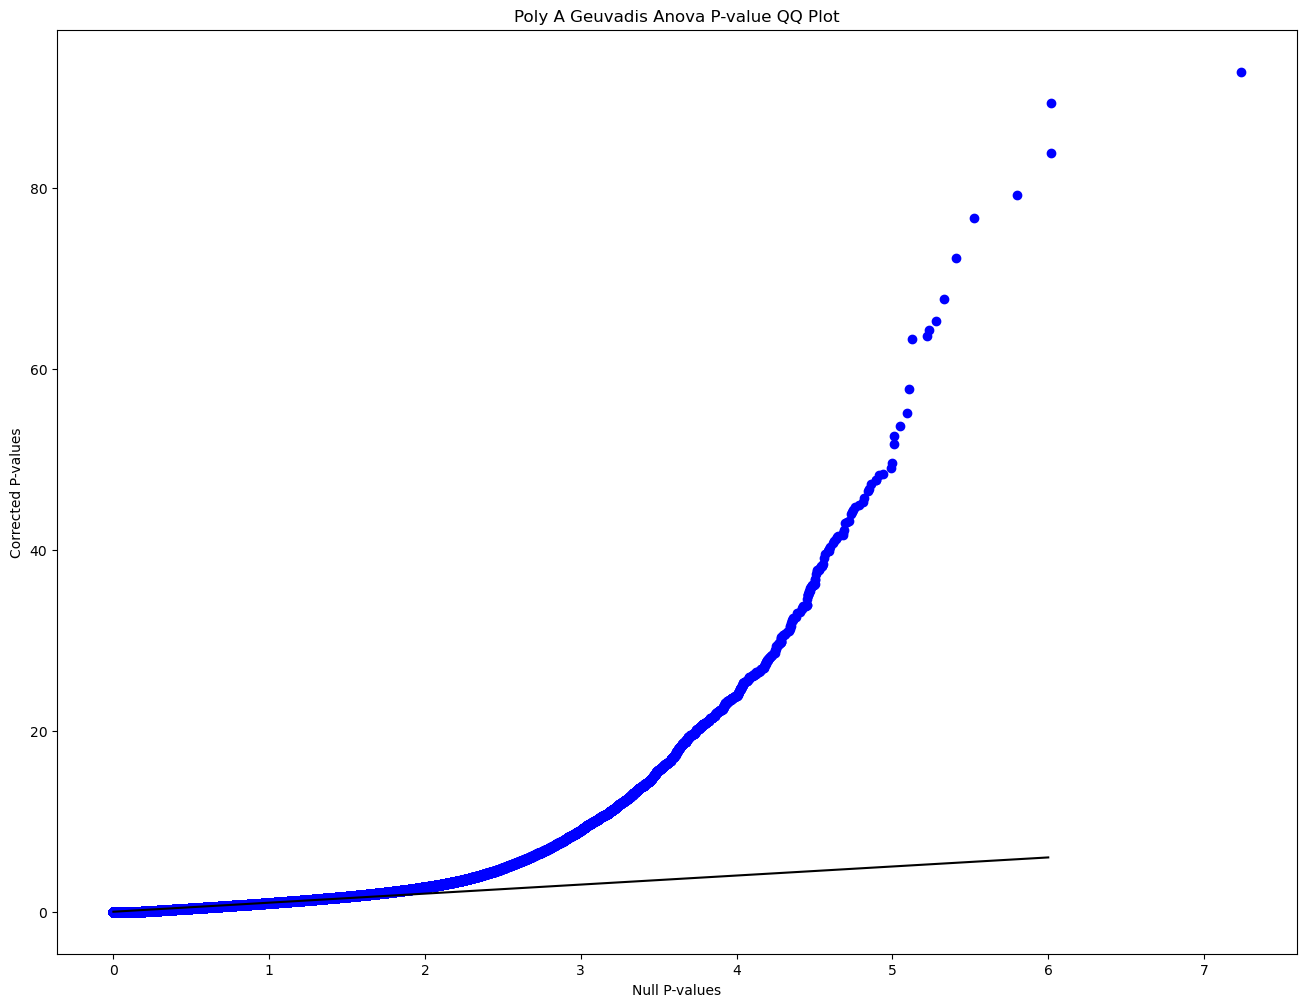

In [11]:
# Check for heterozygosity amongst poly A repeats
repeat_unit = 'A' 
poly_A_het_table = setup_fisher_table(metadata_df[metadata_df['repeat_unit'] == repeat_unit], 'het_EUR', col_thresh=0.10)
pretty_print_table(poly_A_het_table)

# Poly A QQ plot of anova pvals
poly_A_pvals = metadata_df[metadata_df['repeat_unit'] == repeat_unit]['p.anova']
poly_A_pvals = -1*np.log10(poly_A_pvals)
sorted_poly_A_pvals = np.sort(poly_A_pvals)
uniform_pvals = np.random.uniform(size=poly_A_pvals.shape[0])
uniform_pvals = -1*np.log10(uniform_pvals)
sorted_uniform_pvals = np.sort(uniform_pvals)
print(poly_A_pvals.shape[0])
fig = plt.figure(figsize=(16,12))
ax = fig.add_subplot(1,1,1)
ax.set_title("Poly A Geuvadis Anova P-value QQ Plot")
ax.set_xlabel('Null P-values')
ax.set_ylabel("Corrected P-values")
ax.scatter(sorted_uniform_pvals, sorted_poly_A_pvals, color='b')
ax.plot([0, 6], [0, 6], color='black')
plt.show()
